#### Energy distance toy

In [9]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:


def energy_distance_statistic(P, Q):
    """
    Unbiased sample Energy Distance statistic.
    """

    P = np.asarray(P).reshape(-1)
    Q = np.asarray(Q).reshape(-1)

    m = len(P)
    n = len(Q)

    if m < 2 or n < 2:
        raise ValueError(
            "P and Q must each contain at least 2 observations."
        )

    # Pairwise distances
    D_PP = np.abs(P[:, None] - P[None, :])
    D_QQ = np.abs(Q[:, None] - Q[None, :])
    D_PQ = np.abs(P[:, None] - Q[None, :])

    # Remove diagonal terms for unbiased within-sample estimates
    np.fill_diagonal(D_PP, 0)
    np.fill_diagonal(D_QQ, 0)

    term_PQ = 2 * D_PQ.sum() / (m * n)

    term_PP = D_PP.sum() / (m * (m - 1))
    term_QQ = D_QQ.sum() / (n * (n - 1))

    energy = term_PQ - term_PP - term_QQ

    return energy

In [3]:
def energy_permutation_test(
    P,
    Q,
    n_permutations=200,
    alpha=0.05,
    seed=42
):
    """
    Permutation test using the Energy Distance statistic.
    """

    P = np.asarray(P).reshape(-1)
    Q = np.asarray(Q).reshape(-1)

    rng = np.random.default_rng(seed)

    observed_energy = energy_distance_statistic(P, Q)

    combined = np.concatenate([P, Q])

    m = len(P)

    permutation_energy = np.empty(n_permutations)

    for i in range(n_permutations):

        permutation = rng.permutation(len(combined))

        P_perm = combined[permutation[:m]]
        Q_perm = combined[permutation[m:]]

        permutation_energy[i] = energy_distance_statistic(
            P_perm,
            Q_perm
        )

    p_value = (
        1 + np.sum(permutation_energy >= observed_energy)
    ) / (n_permutations + 1)

    reject_H0 = p_value < alpha

    return {
        "energy": observed_energy,
        "p_value": p_value,
        "reject_H0": reject_H0,
        "alpha": alpha,
        "n_permutations": n_permutations,
        "seed": seed,
        "permutation_energy": permutation_energy
    }

In [4]:
def repeat_energy_distance(
    mu_P,
    mu_Q,
    n=300,
    repetitions=100,
    std_P=1.0,
    std_Q=1.0,
    n_permutations=200,
    alpha=0.05
):
    """
    Repeat the Energy Distance permutation test
    on Gaussian toy distributions.
    """

    results = []

    for seed in range(repetitions):

        # Generate a new dataset for each repetition
        rng = np.random.default_rng(seed)

        P = rng.normal(
            loc=mu_P,
            scale=std_P,
            size=n
        )

        Q = rng.normal(
            loc=mu_Q,
            scale=std_Q,
            size=n
        )

        # Separate seed for permutation calibration
        result = energy_permutation_test(
            P,
            Q,
            n_permutations=n_permutations,
            alpha=alpha,
            seed=10000 + seed
        )

        results.append({
            "mu_P": mu_P,
            "mu_Q": mu_Q,
            "mean_difference": abs(mu_Q - mu_P),
            "std_P": std_P,
            "std_Q": std_Q,
            "n": n,
            "energy": result["energy"],
            "p_value": result["p_value"],
            "reject_H0": result["reject_H0"],
            "seed": seed
        })

    return results

In [5]:
# time check before running the experiments

start_time = time.time()

test_results = repeat_energy_distance(
    mu_P=0,
    mu_Q=0,
    n=300,
    repetitions=10,
    std_P=1.0,
    std_Q=1.0,
    n_permutations=200,
    alpha=0.05
)

elapsed_time = time.time() - start_time

print(f"10 repetitions: {elapsed_time:.2f} seconds")
print(
    f"Estimated 100 repetitions: "
    f"{elapsed_time * 10 / 60:.2f} minutes"
)
print(
    f"Estimated 1000 repetitions: "
    f"{elapsed_time * 100 / 60:.2f} minutes"
)

10 repetitions: 2.16 seconds
Estimated 100 repetitions: 0.36 minutes
Estimated 1000 repetitions: 3.60 minutes


#### Mean shift - energy distance

In [6]:
mean_differences = [0.0, 0.1, 0.3, 0.5, 1.0]

repetitions = 1000
n = 300
n_permutations = 200
alpha = 0.05

energy_summary = []
energy_all_results = []

total_start = time.time()

for delta in mean_differences:

    condition_start = time.time()

    print(
        f"\nRunning Energy Distance: "
        f"N(0,1) vs N({delta},1)"
    )

    results = repeat_energy_distance(
        mu_P=0,
        mu_Q=delta,
        n=n,
        repetitions=repetitions,
        std_P=1.0,
        std_Q=1.0,
        n_permutations=n_permutations,
        alpha=alpha
    )

    energy_all_results.extend(results)

    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    interpretation = (
        "Type I error"
        if delta == 0
        else "Power"
    )

    condition_time = time.time() - condition_start

    energy_summary.append({
        "comparison": f"N(0,1) vs N({delta},1)",
        "mean_difference": delta,
        "rejection_rate": rejection_rate,
        "interpretation": interpretation,
        "runtime_minutes": condition_time / 60
    })

    print(
        f"Finished delta={delta} "
        f"in {condition_time / 60:.2f} minutes"
    )

total_time = time.time() - total_start

energy_summary_df = pd.DataFrame(energy_summary)

print("\nFinal Energy Distance summary:")
print(energy_summary_df)

print(
    f"\nTotal elapsed time: "
    f"{total_time / 60:.2f} minutes"
)


Running Energy Distance: N(0,1) vs N(0.0,1)
Finished delta=0.0 in 6.46 minutes

Running Energy Distance: N(0,1) vs N(0.1,1)
Finished delta=0.1 in 2.67 minutes

Running Energy Distance: N(0,1) vs N(0.3,1)
Finished delta=0.3 in 4.28 minutes

Running Energy Distance: N(0,1) vs N(0.5,1)
Finished delta=0.5 in 3.04 minutes

Running Energy Distance: N(0,1) vs N(1.0,1)
Finished delta=1.0 in 3.01 minutes

Final Energy Distance summary:
           comparison  mean_difference  rejection_rate interpretation  \
0  N(0,1) vs N(0.0,1)              0.0           0.055   Type I error   
1  N(0,1) vs N(0.1,1)              0.1           0.221          Power   
2  N(0,1) vs N(0.3,1)              0.3           0.947          Power   
3  N(0,1) vs N(0.5,1)              0.5           1.000          Power   
4  N(0,1) vs N(1.0,1)              1.0           1.000          Power   

   runtime_minutes  
0         6.457204  
1         2.666315  
2         4.281900  
3         3.042076  
4         3.006504  

To

In [7]:
energy_all_results_df = pd.DataFrame(
    energy_all_results
)

energy_all_results_df.to_csv(
    "../results/energy_mean_shift_1000_runs.csv",
    index=False
)

energy_summary_df.to_csv(
    "../results/energy_mean_shift_1000_summary.csv",
    index=False
)

Energy Distance had a Type 1 error of $0.055$, with $\alpha=0.05$. It is very close to the expected error. MMD, with a fixed $\sigma = 1$ baseline, obtained $0.053$, so both tests are answering well under identical dstributions. 

In power, Energy Distance showed better results in difficult scenarios:
- $\delta \mu$ = 0.1
    - MMD    = 0.190
    - Energy = 0.221

- $\delta \mu$ = 0.3
    - MMD    = 0.893
    - Energy = 0.947

Energy Distance showed slightly higher estimated power than the baseline MMD configuration while maintaining a similar Type I error.

#### Variance shift - Energy Distance

Does Energy Distance also detect distributional differences when the mean remains unchanged and only the variance changes?

In [8]:
# Standard deviations for Q
std_Q_values = [1.0, 1.1, 1.3, 1.5, 2.0]

repetitions = 1000
n = 300
n_permutations = 200
alpha = 0.05

energy_variance_summary = []
energy_variance_all_results = []

# Total runtime
total_start = time.time()

for std_Q in std_Q_values:

    condition_start = time.time()

    print(
        f"\nRunning Energy Distance: "
        f"N(0,1) vs N(0,{std_Q**2:.2f}) "
        f"[std_Q={std_Q}]"
    )

    results = repeat_energy_distance(
        mu_P=0,
        mu_Q=0,          # same mean
        n=n,
        repetitions=repetitions,
        std_P=1.0,
        std_Q=std_Q,
        n_permutations=n_permutations,
        alpha=alpha
    )

    energy_variance_all_results.extend(results)

    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    interpretation = (
        "Type I error"
        if std_Q == 1.0
        else "Power"
    )

    condition_time = time.time() - condition_start

    energy_variance_summary.append({
        "std_Q": std_Q,
        "variance_Q": std_Q**2,
        "rejection_rate": rejection_rate,
        "interpretation": interpretation,
        "runtime_minutes": condition_time / 60
    })

    print(
        f"Finished std_Q={std_Q} "
        f"in {condition_time / 60:.2f} minutes"
    )

total_time = time.time() - total_start

energy_variance_summary_df = pd.DataFrame(
    energy_variance_summary
)

print("\nFinal Energy Distance variance-shift summary:")
print(energy_variance_summary_df)

print(
    f"\nTotal elapsed time: "
    f"{total_time / 60:.2f} minutes"
)


Running Energy Distance: N(0,1) vs N(0,1.00) [std_Q=1.0]
Finished std_Q=1.0 in 3.19 minutes

Running Energy Distance: N(0,1) vs N(0,1.21) [std_Q=1.1]
Finished std_Q=1.1 in 2.88 minutes

Running Energy Distance: N(0,1) vs N(0,1.69) [std_Q=1.3]
Finished std_Q=1.3 in 2.70 minutes

Running Energy Distance: N(0,1) vs N(0,2.25) [std_Q=1.5]
Finished std_Q=1.5 in 2.04 minutes

Running Energy Distance: N(0,1) vs N(0,4.00) [std_Q=2.0]
Finished std_Q=2.0 in 2.23 minutes

Final Energy Distance variance-shift summary:
   std_Q  variance_Q  rejection_rate interpretation  runtime_minutes
0    1.0        1.00           0.055   Type I error         3.188888
1    1.1        1.21           0.099          Power         2.876270
2    1.3        1.69           0.718          Power         2.698291
3    1.5        2.25           0.994          Power         2.038268
4    2.0        4.00           1.000          Power         2.231666

Total elapsed time: 13.03 minutes


In [10]:
energy_variance_all_results_df = pd.DataFrame(
    energy_variance_all_results
)

energy_variance_all_results_df.to_csv(
    "../results/energy_variance_shift_1000_runs.csv",
    index=False
)

energy_variance_summary_df.to_csv(
    "../results/energy_variance_shift_1000_summary.csv",
    index=False
)

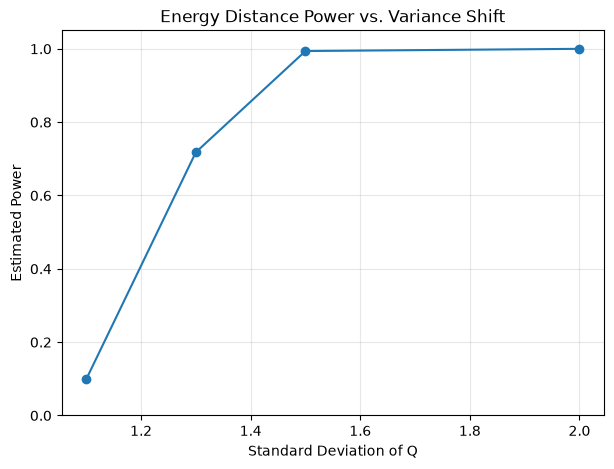

In [11]:
energy_variance_power_df = energy_variance_summary_df[
    energy_variance_summary_df["std_Q"] > 1.0
]

plt.figure(figsize=(7, 5))

plt.plot(
    energy_variance_power_df["std_Q"],
    energy_variance_power_df["rejection_rate"],
    marker="o"
)

plt.xlabel("Standard Deviation of Q")
plt.ylabel("Estimated Power")
plt.title("Energy Distance Power vs. Variance Shift")

plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)

plt.show()

With identical distributions, a $ \text{Type I error}=0.055 $ was obtained with $\alpha=0.05$, which was expected as well. Later, as the variance difference increases, the power of the test increases as well.  This confirms that Energy Distance is able to detect changes in the distribution that are not simply mean shifts. 

In the preliminary variance-shift experiments, MMD showed higher estimated power than Energy Distance for small and moderate variance differences. However, the MMD estimates were based on fewer repetitions (100 with MMD, 1000 with ED), so the comparison should be interpreted cautiously.

| std(Q) |      MMD | Energy Distance |
| -----: | -------: | --------------: |
|    1.0 |     0.08 |       **0.055** |
|    1.1 | **0.22** |           0.099 |
|    1.3 | **0.91** |           0.718 |
|    1.5 |     1.00 |           0.994 |
|    2.0 |     1.00 |           1.000 |


The mean-shift and variance-shift experiments showed that metric sensitivity depends not only on the magnitude of a defect but also on the type of distributional difference being introduced.

#### C2ST with variance-shift

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest

In [18]:
def c2st(P, Q, test_size=0.5, seed=42, alpha=0.05):

    # Combine samples
    X = np.concatenate([P, Q]).reshape(-1, 1)

    # Origin labels
    y = np.concatenate([
        np.zeros(len(P), dtype=int),
        np.ones(len(Q), dtype=int)
    ])

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=seed,
        stratify=y
    )

    # Binary classifier
    classifier = LogisticRegression(
        random_state=seed
    )

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    correct = np.sum(predictions == y_test)
    n_test = len(y_test)

    accuracy = correct / n_test

    # Exact test under H0: accuracy = 0.5
    p_value = binomtest(
        correct,
        n=n_test,
        p=0.5,
        alternative="greater"
    ).pvalue

    return {
        "accuracy": accuracy,
        "p_value": p_value,
        "reject_H0": p_value < alpha,
        "correct": correct,
        "n_test": n_test,
        "seed": seed
    }

In [19]:
def repeat_c2st_variance_shift(
    std_P,
    std_Q,
    n=300,
    repetitions=1000,
    alpha=0.05
):
    """
    Repeat C2ST on Gaussian distributions with
    equal means but different standard deviations.

    P ~ N(0, std_P^2)
    Q ~ N(0, std_Q^2)
    """

    results = []

    for seed in range(repetitions):

        rng = np.random.default_rng(seed)

        P = rng.normal(
            loc=0,
            scale=std_P,
            size=n
        )

        Q = rng.normal(
            loc=0,
            scale=std_Q,
            size=n
        )

        result = c2st(
            P,
            Q,
            test_size=0.5,
            seed=seed,
            alpha=alpha
        )

        results.append({
            "std_P": std_P,
            "std_Q": std_Q,
            "variance_P": std_P**2,
            "variance_Q": std_Q**2,
            "n": n,
            "accuracy": result["accuracy"],
            "p_value": result["p_value"],
            "reject_H0": result["reject_H0"],
            "seed": seed
        })

    return results

In [20]:
c2st_variance_summary = []
c2st_variance_all_results = []

total_start = time.time()

for std_Q in std_Q_values:

    condition_start = time.time()

    print(
        f"\nRunning C2ST: "
        f"N(0,1) vs N(0,{std_Q**2:.2f}) "
        f"[std_Q={std_Q}]"
    )

    results = repeat_c2st_variance_shift(
        std_P=1.0,
        std_Q=std_Q,
        n=n,
        repetitions=repetitions,
        alpha=alpha
    )

    c2st_variance_all_results.extend(results)

    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    mean_accuracy = np.mean([
        result["accuracy"]
        for result in results
    ])

    interpretation = (
        "Type I error"
        if std_Q == 1.0
        else "Power"
    )

    condition_time = time.time() - condition_start

    c2st_variance_summary.append({
        "std_Q": std_Q,
        "variance_Q": std_Q**2,
        "mean_accuracy": mean_accuracy,
        "rejection_rate": rejection_rate,
        "interpretation": interpretation,
        "runtime_minutes": condition_time / 60
    })

    print(
        f"Finished std_Q={std_Q} "
        f"in {condition_time / 60:.2f} minutes"
    )

total_time = time.time() - total_start

c2st_variance_summary_df = pd.DataFrame(
    c2st_variance_summary
)

print("\nFinal C2ST variance-shift summary:")
print(c2st_variance_summary_df)

print(
    f"\nTotal elapsed time: "
    f"{total_time / 60:.2f} minutes"
)


Running C2ST: N(0,1) vs N(0,1.00) [std_Q=1.0]


Finished std_Q=1.0 in 0.26 minutes

Running C2ST: N(0,1) vs N(0,1.21) [std_Q=1.1]
Finished std_Q=1.1 in 0.23 minutes

Running C2ST: N(0,1) vs N(0,1.69) [std_Q=1.3]
Finished std_Q=1.3 in 0.21 minutes

Running C2ST: N(0,1) vs N(0,2.25) [std_Q=1.5]
Finished std_Q=1.5 in 0.10 minutes

Running C2ST: N(0,1) vs N(0,4.00) [std_Q=2.0]
Finished std_Q=2.0 in 0.21 minutes

Final C2ST variance-shift summary:
   std_Q  variance_Q  mean_accuracy  rejection_rate interpretation  \
0    1.0        1.00       0.499697           0.028   Type I error   
1    1.1        1.21       0.500133           0.034          Power   
2    1.3        1.69       0.500410           0.037          Power   
3    1.5        2.25       0.501007           0.043          Power   
4    2.0        4.00       0.504260           0.059          Power   

   runtime_minutes  
0         0.257755  
1         0.225899  
2         0.213658  
3         0.104376  
4         0.211023  

Total elapsed time: 1.01 minutes


In [21]:
c2st_variance_all_results_df = pd.DataFrame(
    c2st_variance_all_results
)

c2st_variance_all_results_df.to_csv(
    "../results/c2st_variance_shift_1000_runs.csv",
    index=False
)

c2st_variance_summary_df.to_csv(
    "../results/c2st_variance_shift_1000_summary.csv",
    index=False
)

**Important known-answer failure**

Despite the variance for $Q$ being 4 times larger, accuracy remains at ~$0.5$, whereas rejection rate only goes up to $0.59$.

The result is explained by classifier capacity. A one-dimensional Logistic Regression classifier learns a linear decision boundary, while distinguishing two zero-mean Gaussian distributions with different variances requires a two-sided decision rule in which observations with large absolute values are more likely to belong to the higher-variance distribution.

Failure of a C2ST to distinguish two distributions does not imply that the distributions are equal. It may instead indicate that the chosen classifier lacks the capacity to detect the particular difference.